# OCR baseline


In [1]:
from pathlib import Path
from PIL import Image

import pandas as pd
import matplotlib.pyplot as plt
import pytesseract

from jiwer import cer, wer
from tqdm import tqdm

print("Tesseract version:", pytesseract.get_tesseract_version())
print("Available languages:", pytesseract.get_languages(config=""))

Tesseract version: 5.5.3
Available languages: ['afr', 'amh', 'ara', 'asm', 'aze', 'aze_cyrl', 'bel', 'ben', 'bod', 'bos', 'bre', 'bul', 'cat', 'ceb', 'ces', 'chi_sim', 'chi_sim_vert', 'chi_tra', 'chi_tra_vert', 'chr', 'cos', 'cym', 'dan', 'deu', 'div', 'dzo', 'ell', 'eng', 'enm', 'epo', 'equ', 'est', 'eus', 'fao', 'fas', 'fil', 'fin', 'fra', 'frk', 'frm', 'fry', 'gla', 'gle', 'glg', 'grc', 'guj', 'hat', 'heb', 'hin', 'hrv', 'hun', 'hye', 'iku', 'ind', 'isl', 'ita', 'ita_old', 'jav', 'jpn', 'jpn_vert', 'kan', 'kat', 'kat_old', 'kaz', 'khm', 'kir', 'kmr', 'kor', 'kor_vert', 'lao', 'lat', 'lav', 'lit', 'ltz', 'mal', 'mar', 'mkd', 'mlt', 'mon', 'mri', 'msa', 'mya', 'nep', 'nld', 'nor', 'oci', 'ori', 'osd', 'pan', 'pol', 'por', 'pus', 'que', 'ron', 'rus', 'san', 'sin', 'slk', 'slv', 'snd', 'spa', 'spa_old', 'sqi', 'srp', 'srp_latn', 'sun', 'swa', 'swe', 'syr', 'tam', 'tat', 'tel', 'tgk', 'tha', 'tir', 'ton', 'tur', 'uig', 'ukr', 'urd', 'uzb', 'uzb_cyrl', 'vie', 'yid', 'yor']


In [2]:
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "requirements.txt").is_file() and (p / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the cloned project folder or notebooks/.")

csv_path = PROJECT_ROOT / "data/processed/line_metadata.csv"

df = pd.read_csv(csv_path, keep_default_na=False)

print("Total lines:", len(df))
print("Pages:", df["page_id"].nunique())

print(df.head().to_string())

Total lines: 164
Pages: 4


,page_id,line_id,image_path,ground_truth,x_min,y_min,x_max,y_max,crop_width,crop_height
0,bebel_frau_1879_0146,l7,../data/processed/line_images/bebel_frau_1879_...,— 140 —,1274,119,1755,173,481,54
1,bebel_frau_1879_0146,l11,../data/processed/line_images/bebel_frau_1879_...,hochbedeutsame Gartenwirthschaft ihre allersch...,250,291,2785,353,2535,62
2,bebel_frau_1879_0146,l12,../data/processed/line_images/bebel_frau_1879_...,falten.,250,383,456,441,206,58
3,bebel_frau_1879_0146,l14,../data/processed/line_images/bebel_frau_1879_...,"Sicher giebt es keine gesündere und, wenn mit ...",429,468,2787,543,2358,75
4,bebel_frau_1879_0146,l16,../data/processed/line_images/bebel_frau_1879_...,auch keine angenehmere Beschäftigung wie die G...,249,556,2788,628,2539,72


In [3]:
def resolve_image_path(saved_path):
    path = Path(saved_path)
    candidates = [path] if path.is_absolute() else [
        PROJECT_ROOT / path,
        PROJECT_ROOT / "notebooks" / path,
    ]
    candidates.append(PROJECT_ROOT / "data/processed/line_images" / path.name)
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not resolve line image: {saved_path}")

df["resolved_image_path"] = df["image_path"].apply(resolve_image_path)
missing = df[~df["resolved_image_path"].apply(lambda p: p.is_file())]
print("Missing images:", len(missing))
assert len(missing) == 0, "Some image paths are invalid."


Missing images: 0


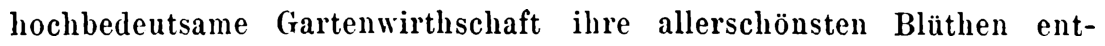

Ground truth:
hochbedeutsame Gartenwirthschaft ihre allerschönsten Blüthen ent-


In [4]:
sample = df[
    (df["page_id"] == "bebel_frau_1879_0146") &
    (df["line_id"] == "l11")
].iloc[0]

with Image.open(sample["resolved_image_path"]) as img:
    line_image = img.convert("RGB")

plt.figure(figsize=(14, 3))
plt.imshow(line_image)
plt.axis("off")
plt.show()

print("Ground truth:")
print(sample["ground_truth"])

In [5]:
ocr_text = pytesseract.image_to_string(
    line_image,
    lang="deu",
    config="--psm 7"
).strip()

print("OCR prediction:")
print(ocr_text)

print("\nGround truth:")
print(sample["ground_truth"])

OCR prediction:
hochbedeutsame Gartenwirthschaft ıhre allerschönsten Blüthen ent-

Ground truth:
hochbedeutsame Gartenwirthschaft ihre allerschönsten Blüthen ent-


In [6]:
ground_truth = sample["ground_truth"]

line_cer = cer(ground_truth, ocr_text)
line_wer = wer(ground_truth, ocr_text)

print(f"Character Error Rate: {line_cer:.2%}")
print(f"Word Error Rate: {line_wer:.2%}")

Character Error Rate: 1.54%
Word Error Rate: 16.67%


In [8]:
import time
from tqdm import tqdm

ocr_predictions = []
processing_times = []

for _, row in tqdm(df.iterrows(), total=len(df)):

    with Image.open(row["resolved_image_path"]) as img:
        line_image = img.convert("RGB")

    start = time.perf_counter()

    prediction = pytesseract.image_to_string(
        line_image,
        lang="deu",
        config="--psm 7"
    ).strip()

    elapsed = time.perf_counter() - start

    ocr_predictions.append(prediction)
    processing_times.append(elapsed)

df["ocr_text"] = ocr_predictions
df["ocr_time_seconds"] = processing_times

print("OCR completed for:", len(df), "lines")

print(df[["page_id", "line_id", "ground_truth", "ocr_text"]].head().to_string())

100%|██████████| 164/164 [00:45<00:00,  3.63it/s]

OCR completed for: 164 lines


,page_id,line_id,ground_truth,ocr_text
0,bebel_frau_1879_0146,l7,— 140 —,— 71419 —
1,bebel_frau_1879_0146,l11,hochbedeutsame Gartenwirthschaft ihre allersch...,hochbedeutsame Gartenwirthschaft ıhre allersch...
2,bebel_frau_1879_0146,l12,falten.,falten.
3,bebel_frau_1879_0146,l14,"Sicher giebt es keine gesündere und, wenn mit ...","Sicher giebt es keine gesündere und, wenn mit ..."
4,bebel_frau_1879_0146,l16,auch keine angenehmere Beschäftigung wie die G...,auch keine angenehmere Beschäftigung wie die G...


In [9]:
df["cer"] = df.apply(
    lambda row: cer(
        row["ground_truth"],
        row["ocr_text"]
    ),
    axis=1
)

df["wer"] = df.apply(
    lambda row: wer(
        row["ground_truth"],
        row["ocr_text"]
    ),
    axis=1
)

print(df[[
        "page_id",
        "line_id",
        "ground_truth",
        "ocr_text",
        "cer",
        "wer"
    ]].head().to_string())

,page_id,line_id,ground_truth,ocr_text,cer,wer
0,bebel_frau_1879_0146,l7,— 140 —,— 71419 —,0.428571,0.333333
1,bebel_frau_1879_0146,l11,hochbedeutsame Gartenwirthschaft ihre allersch...,hochbedeutsame Gartenwirthschaft ıhre allersch...,0.015385,0.166667
2,bebel_frau_1879_0146,l12,falten.,falten.,0.000000,0.000000
3,bebel_frau_1879_0146,l14,"Sicher giebt es keine gesündere und, wenn mit ...","Sicher giebt es keine gesündere und, wenn mit ...",0.000000,0.000000
4,bebel_frau_1879_0146,l16,auch keine angenehmere Beschäftigung wie die G...,auch keine angenehmere Beschäftigung wie die G...,0.000000,0.000000


In [10]:
overall_cer = cer(
    df["ground_truth"].tolist(),
    df["ocr_text"].tolist()
)

overall_wer = wer(
    df["ground_truth"].tolist(),
    df["ocr_text"].tolist()
)

print("=== Tesseract OCR Baseline ===")
print("Number of lines:", len(df))
print(f"Overall CER: {overall_cer:.2%}")
print(f"Overall WER: {overall_wer:.2%}")
print(f"Mean time per line: {df['ocr_time_seconds'].mean():.3f} seconds")

=== Tesseract OCR Baseline ===
Number of lines: 164
Overall CER: 1.34%
Overall WER: 8.25%
Mean time per line: 0.269 seconds


In [11]:
worst_lines = df.sort_values(
    "cer",
    ascending=False
).head(10)

print(worst_lines[[
        "page_id",
        "line_id",
        "ground_truth",
        "ocr_text",
        "cer"
    ]].to_string())

,page_id,line_id,ground_truth,ocr_text,cer
0,bebel_frau_1879_0146,l7,— 140 —,— 71419 —,0.428571
105,bebel_frau_1879_0176,l9,— 170 —,— 1X) —,0.285714
21,bebel_frau_1879_0146,l34,sammenfassen :,sammenfassen,0.142857
111,bebel_frau_1879_0176,l18,Möglichkeit dazu sich herausstellt.,Möcelıchkeit dazu sıch herausstellt.,0.114286
23,bebel_frau_1879_0146,l36,seitigt*).,seitigt”).,0.100000
154,bebel_frau_1879_0176,l65,"***) So sorgt der Herr, dass Hirsch und Ochs,","Er) So sorgt der Herr. dass Hirsch und Ochs,",0.088889
104,bebel_frau_1879_0168,l59,andern Tage durch Conventbeschluss wieder eins...,andern Tace durch Conventbeschluss wieder eins...,0.078947
82,bebel_frau_1879_0168,l35,Gegen diese Kraftsprache ist das Condorcet-Bri...,Gegen diese Kraftsprache ıst das Condorcet -Br...,0.056338
43,bebel_frau_1879_0146,l64,in seiner jetzigen Stellung ein nützliches Cul...,In seiner jetzieen Stellung ein nützliches Cul...,0.053333
155,bebel_frau_1879_0176,l66,"Das heisst: dass ihn sein Bauer mäste,","Das heisst: dass ıhn sein Dauer mäste,",0.052632


In [12]:
page_results = []

for page_id, group in df.groupby("page_id"):
    page_results.append({
        "page_id": page_id,
        "lines": len(group),
        "cer": cer(
            group["ground_truth"].tolist(),
            group["ocr_text"].tolist()
        ),
        "wer": wer(
            group["ground_truth"].tolist(),
            group["ocr_text"].tolist()
        )
    })

page_results = pd.DataFrame(page_results)

print(page_results.to_string())

,page_id,lines,cer,wer
0,bebel_frau_1879_0146,50,0.012000,0.078431
1,bebel_frau_1879_0168,55,0.014978,0.087591
2,bebel_frau_1879_0176,51,0.013711,0.084711
3,bebel_frau_1879_0186,8,0.007264,0.047619


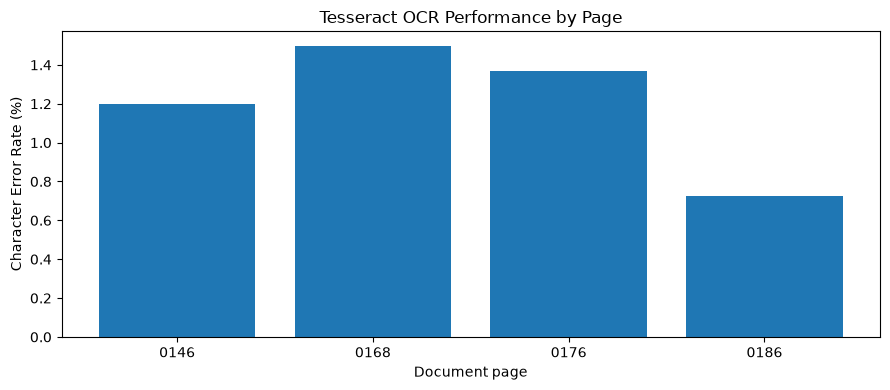

In [13]:
plt.figure(figsize=(9, 4))

plt.bar(
    page_results["page_id"].str[-4:],
    page_results["cer"] * 100
)

plt.xlabel("Document page")
plt.ylabel("Character Error Rate (%)")
plt.title("Tesseract OCR Performance by Page")

plt.tight_layout()
plt.show()

In [14]:
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

df.assign(resolved_image_path=df["image_path"]).to_csv(
    results_dir / "tesseract_baseline.csv",
    index=False,
    encoding="utf-8"
)

page_results.to_csv(
    results_dir / "tesseract_page_results.csv",
    index=False,
    encoding="utf-8"
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


In [15]:
from pytesseract import Output

confidence_data = pytesseract.image_to_data(
    line_image,
    lang="deu",
    config="--psm 7",
    output_type=Output.DATAFRAME
)

print(confidence_data[
        ["text", "conf"]
    ].dropna(subset=["text"]).to_string())

,text,conf
4,Schweizerische,93.260971
5,Vereinsbuchdruckerei.,91.449203
6,Hottingen,91.661118
7,-,91.661118
8,Zürich.,96.640366


## Line-Level OCR Confidence Analysis

In [16]:
import numpy as np
from pytesseract import Output

line_confidences = []

for _, row in tqdm(df.iterrows(), total=len(df)):

    with Image.open(row["resolved_image_path"]) as img:
        line_image = img.convert("RGB")

    data = pytesseract.image_to_data(
        line_image,
        lang="deu",
        config="--psm 7",
        output_type=Output.DATAFRAME
    )

    # Keep only valid recognized words
    valid_words = data[
        (data["conf"] >= 0) &
        (data["text"].notna()) &
        (data["text"].astype(str).str.strip() != "")
    ]

    if len(valid_words) > 0:
        mean_confidence = valid_words["conf"].mean()
    else:
        mean_confidence = np.nan

    line_confidences.append(mean_confidence)

df["ocr_confidence"] = line_confidences

print(df[["line_id", "ocr_confidence", "cer", "wer"]].head(10).to_string())

100%|██████████| 164/164 [00:50<00:00,  3.25it/s]


,line_id,ocr_confidence,cer,wer
0,l7,74.153135,0.428571,0.333333
1,l11,89.737741,0.015385,0.166667
2,l12,96.140396,0.000000,0.000000
3,l14,94.373511,0.000000,0.000000
4,l16,91.094825,0.000000,0.000000
5,l17,93.088201,0.030769,0.250000
6,l18,92.274145,0.029412,0.222222
7,l19,91.535599,0.000000,0.000000
8,l21,94.706944,0.000000,0.000000
9,l22,91.177142,0.018519,0.142857


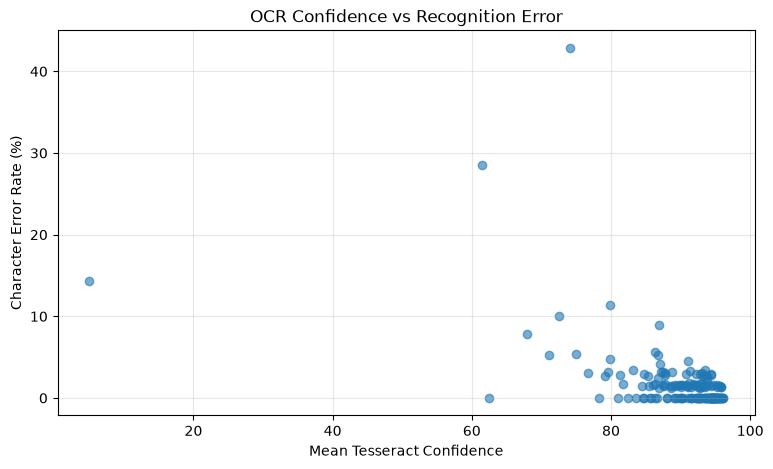

In [17]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["ocr_confidence"],
    df["cer"] * 100,
    alpha=0.6
)

plt.xlabel("Mean Tesseract Confidence")
plt.ylabel("Character Error Rate (%)")
plt.title("OCR Confidence vs Recognition Error")
plt.grid(alpha=0.3)

plt.show()

In [19]:
valid = df.dropna(subset=["ocr_confidence", "cer"])

pearson = valid["ocr_confidence"].corr(
    valid["cer"],
    method="pearson"
)

spearman = valid["ocr_confidence"].corr(
    valid["cer"],
    method="spearman"
)

print(f"Pearson correlation:  {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

Pearson correlation:  -0.5198
Spearman correlation: -0.4858


In [20]:
low_confidence = df.sort_values(
    "ocr_confidence",
    ascending=True
).head(10)

print(low_confidence[[
        "page_id",
        "line_id",
        "ground_truth",
        "ocr_text",
        "ocr_confidence",
        "cer"
    ]].to_string())

,page_id,line_id,ground_truth,ocr_text,ocr_confidence,cer
21,bebel_frau_1879_0146,l34,sammenfassen :,sammenfassen,5.040161,0.142857
105,bebel_frau_1879_0176,l9,— 170 —,— 1X) —,61.424169,0.285714
50,bebel_frau_1879_0168,l22,— 162 —,— 162 —,62.485026,0.000000
104,bebel_frau_1879_0168,l59,andern Tage durch Conventbeschluss wieder eins...,andern Tace durch Conventbeschluss wieder eins...,67.926064,0.078947
152,bebel_frau_1879_0176,l62,... All dieses Jagdland ist durchaus unprodukt...,.. . All dieses Jagdland ist durchaus unproduk...,71.057283,0.052632
23,bebel_frau_1879_0146,l36,seitigt*).,seitigt”).,72.472595,0.100000
0,bebel_frau_1879_0146,l7,— 140 —,— 71419 —,74.153135,0.428571
43,bebel_frau_1879_0146,l64,in seiner jetzigen Stellung ein nützliches Cul...,In seiner jetzieen Stellung ein nützliches Cul...,74.966041,0.053333
51,bebel_frau_1879_0168,l1,negirend gegen sie verhält. Die sozialistische...,neeirend gegen sıe verhält. Die sozialistische...,76.759419,0.030303
93,bebel_frau_1879_0168,l46,**) Wenn die neue Gesellschaft die vorbezeichn...,**) Wenn die neue Gesellschaft die vorbezeichn...,78.322670,0.000000


In [21]:
df.assign(resolved_image_path=df["image_path"]).to_csv(
    results_dir / "tesseract_baseline.csv",
    index=False,
    encoding="utf-8"
)

print("Updated baseline saved with OCR confidence.")

Updated baseline saved with OCR confidence.


## Exploring Confidence Thresholds

In [22]:
thresholds = [70, 80, 85, 90, 95]

results = []

for threshold in thresholds:
    selected = df[df["ocr_confidence"] < threshold]

    results.append({
        "threshold": threshold,
        "selected_lines": len(selected),
        "selection_rate": len(selected) / len(df) * 100,
        "lines_with_errors": (selected["cer"] > 0).sum(),
        "mean_cer": selected["cer"].mean() if len(selected) else None
    })

threshold_df = pd.DataFrame(results)

print(threshold_df.to_string())

,threshold,selected_lines,selection_rate,lines_with_errors,mean_cer
0,70,4,2.439024,3,0.126880
1,80,14,8.536585,12,0.099566
2,85,24,14.634146,17,0.063246
3,90,59,35.975610,41,0.036623
4,95,141,85.975610,77,0.020558


In [23]:
total_error_lines = (df["cer"] > 0).sum()

for threshold in [70, 80, 85, 90, 95]:

    selected = df[df["ocr_confidence"] < threshold]

    true_positives = (selected["cer"] > 0).sum()

    precision = (
        true_positives / len(selected)
        if len(selected) else 0
    )

    recall = (
        true_positives / total_error_lines
        if total_error_lines else 0
    )

    print(
        f"Threshold {threshold}: "
        f"Precision={precision:.2%}, "
        f"Recall={recall:.2%}"
    )

Threshold 70: Precision=75.00%, Recall=3.61%
Threshold 80: Precision=85.71%, Recall=14.46%
Threshold 85: Precision=70.83%, Recall=20.48%
Threshold 90: Precision=69.49%, Recall=49.40%
Threshold 95: Precision=54.61%, Recall=92.77%
